In [1]:
# 1. Download 2 years of daily prices
import yfinance as yf, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import norm

price = yf.download("NVDA", start="2024-11-01", end="2026-11-01", auto_adjust=True)["Close"].squeeze()
print(price.head(), len(price))

c:\Users\ROWTECH\AppData\Local\Programs\Python\Python313\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.5.0) or chardet (7.1.0)/charset_normalizer (3.4.0) doesn't match a supported version!
  warnings.warn(
[*********************100%***********************]  1 of 1 completed

Date
2024-11-01    135.037643
2024-11-04    135.685913
2024-11-05    139.535614
2024-11-06    145.220337
2024-11-07    148.481583
Name: NVDA, dtype: float64 500


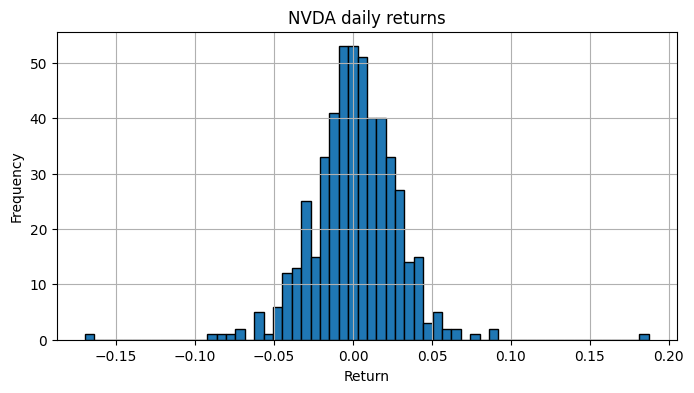

In [2]:
# 2. Daily returns + histogram
ret = price.pct_change().dropna()
ret.hist(bins=60, edgecolor="black", figsize=(8, 4))
plt.title("NVDA daily returns"); plt.xlabel("Return"); plt.ylabel("Frequency"); plt.show()

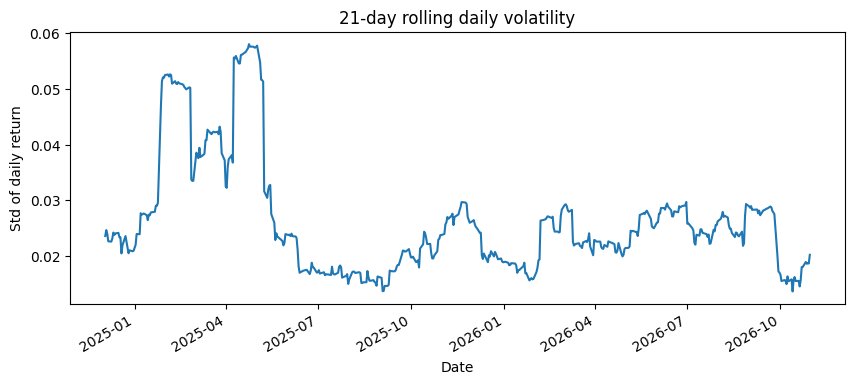

Overall daily volatility: 0.0276 | annualized: 0.4386


In [3]:
# 3. Daily volatility over time (21-day rolling standard deviation ≈ 1 month)
vol = ret.rolling(21).std()
vol.plot(figsize=(10, 4), title="21-day rolling daily volatility"); plt.ylabel("Std of daily return"); plt.show()
print("Overall daily volatility:", round(ret.std(), 4), "| annualized:", round(ret.std() * np.sqrt(252), 4))

In [4]:
# 4–5. Historical and parametric VaR (shown as positive loss)
mu, sigma = ret.mean(), ret.std()
var = pd.DataFrame({
    "Historical VaR": [-np.percentile(ret, 5), -np.percentile(ret, 1)],
    "Parametric VaR": [-(mu + norm.ppf(0.05) * sigma), -(mu + norm.ppf(0.01) * sigma)],
}, index=["95%", "99%"])
print(var.round(4))

     Historical VaR  Parametric VaR
95%          0.0416          0.0442
99%          0.0688          0.0631


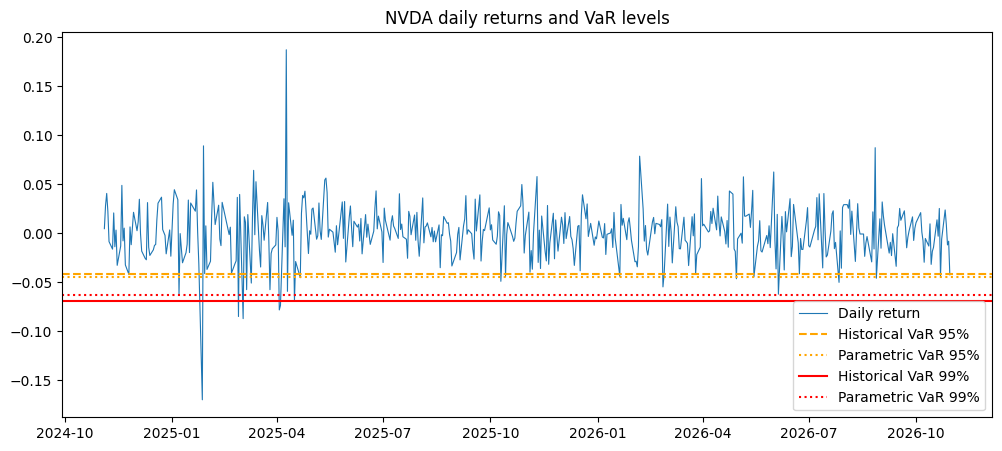

In [5]:
# 6. Returns with VaR levels
plt.figure(figsize=(12, 5))
plt.plot(ret.index, ret, lw=0.8, label="Daily return")
for (lvl, col), ls in zip([("95%", "orange"), ("99%", "red")], ["--", "-"]):
    plt.axhline(-var.loc[lvl, "Historical VaR"], color=col, ls=ls, label=f"Historical VaR {lvl}")
    plt.axhline(-var.loc[lvl, "Parametric VaR"], color=col, ls=":", label=f"Parametric VaR {lvl}")
plt.title("NVDA daily returns and VaR levels"); plt.legend(); plt.show()

In [6]:
# 7. Compare: how often did losses exceed each VaR? (expected: 5% and 1% of days)
for lvl, p in [("95%", 0.05), ("99%", 0.01)]:
    for m in var.columns:
        print(f"{m} {lvl}: breaches = {(ret < -var.loc[lvl, m]).mean():.2%} (expected {p:.0%})")
print("Kurtosis (normal = 0):", round(ret.kurt(), 2))

Historical VaR 95%: breaches = 5.01% (expected 5%)
Parametric VaR 95%: breaches = 3.61% (expected 5%)
Historical VaR 99%: breaches = 1.00% (expected 1%)
Parametric VaR 99%: breaches = 1.20% (expected 1%)
Kurtosis (normal = 0): 6.82


VaR tells how much the stock can lose in one day at a given confidence level. A 95% historical VaR of X% means that on 95% of days the loss was smaller than X%, and on about 1 day in 20 it was larger.

At 95% the historical and parametric VaR are usually close. At 99% the historical VaR is typically larger, because real returns have fat tails (kurtosis above 0). Extreme losses happen more often than the normal distribution assumes, so the parametric 99% VaR underestimates tail risk. The breach count in step 7 shows this: losses beyond the parametric 99% VaR occur more often than 1% of days.

The rolling volatility plot shows that risk is not constant: it clusters in calm and turbulent periods. A single VaR figure based on the whole period can therefore be too low in volatile times.

Both methods have limits. Historical VaR assumes the past repeats. Parametric VaR assumes normality. Neither says how large the loss can be beyond the VaR level, which is why Expected Shortfall (CVaR) is often used alongside it.